# What Drives NBA Player Improvement?

This project analyzes NBA player data across multiple seasons to determine what factors contribute most to player improvement.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving all_seasons.csv to all_seasons.csv


In [ ]:
import pandas as pd

df = pd.read_csv("all_seasons.csv")
df.head()

,Unnamed: 0,player_name,team_abbreviation,age,player_height,player_weight,college,country,draft_year,draft_round,...,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct,season
0,0,Randy Livingston,HOU,22.0,193.04,94.800728,Louisiana State,USA,1996,2,...,3.9,1.5,2.4,0.3,0.042,0.071,0.169,0.487,0.248,1996-97
1,1,Gaylon Nickerson,WAS,28.0,190.50,86.182480,Northwestern Oklahoma,USA,1994,2,...,3.8,1.3,0.3,8.9,0.030,0.111,0.174,0.497,0.043,1996-97
2,2,George Lynch,VAN,26.0,203.20,103.418976,North Carolina,USA,1993,1,...,8.3,6.4,1.9,-8.2,0.106,0.185,0.175,0.512,0.125,1996-97
3,3,George McCloud,LAL,30.0,203.20,102.058200,Florida State,USA,1989,1,...,10.2,2.8,1.7,-2.7,0.027,0.111,0.206,0.527,0.125,1996-97
4,4,George Zidek,DEN,23.0,213.36,119.748288,UCLA,USA,1995,1,...,2.8,1.7,0.3,-14.1,0.102,0.169,0.195,0.500,0.064,1996-97


In [ ]:
df = df.drop(columns=["Unnamed: 0"])

In [ ]:
df = df.sort_values(by=["player_name", "season"])

In [ ]:
df["pts_next"] = df.groupby("player_name")["pts"].shift(-1)
df["ast_next"] = df.groupby("player_name")["ast"].shift(-1)
df["ts_pct_next"] = df.groupby("player_name")["ts_pct"].shift(-1)
df["usg_pct_next"] = df.groupby("player_name")["usg_pct"].shift(-1)
df["gp_next"] = df.groupby("player_name")["gp"].shift(-1)

In [ ]:
df[["player_name", "season", "pts", "pts_next"]].head(10)

,player_name,season,pts,pts_next
419,A.C. Green,1996-97,7.2,7.3
667,A.C. Green,1997-98,7.3,4.9
1006,A.C. Green,1998-99,4.9,5.0
1626,A.C. Green,1999-00,5.0,4.5
1971,A.C. Green,2000-01,4.5,NaN
1625,A.J. Bramlett,1999-00,1.0,NaN
1970,A.J. Guyton,2000-01,6.0,5.4
2613,A.J. Guyton,2001-02,5.4,0.0
2929,A.J. Guyton,2002-03,0.0,NaN
12588,A.J. Lawson,2022-23,3.7,NaN


In [ ]:
df = df.dropna(subset=["pts_next"])

In [ ]:
df["improvement"] = (
    (df["pts_next"] - df["pts"]) +
    0.5 * (df["ast_next"] - df["ast"]) +
    10 * (df["ts_pct_next"] - df["ts_pct"]) +
    0.3 * (df["usg_pct_next"] - df["usg_pct"])
)

In [ ]:
df[["player_name", "season", "improvement"]].head()

,player_name,season,improvement
419,A.C. Green,1996-97,0.1797
667,A.C. Green,1997-98,-3.4410
1006,A.C. Green,1998-99,0.7489
1626,A.C. Green,1999-00,-0.6410
1970,A.J. Guyton,2000-01,-0.8144


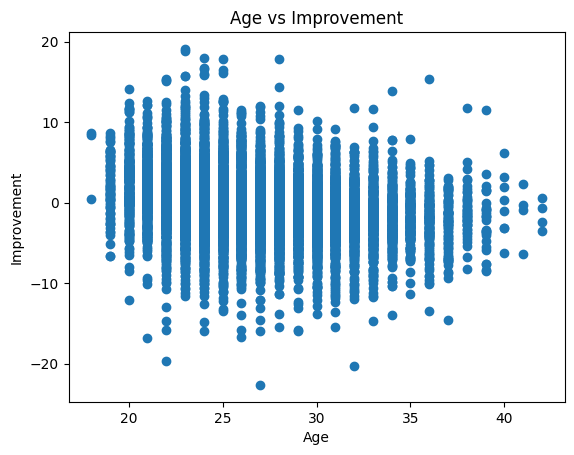

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["age"], df["improvement"])
plt.xlabel("Age")
plt.ylabel("Improvement")
plt.title("Age vs Improvement")
plt.show()

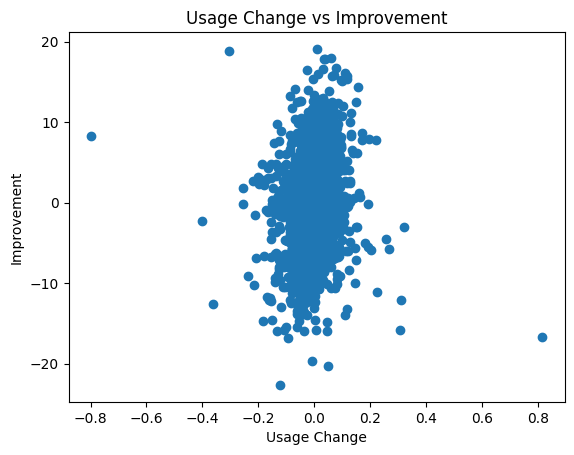

In [ ]:
df["usg_change"] = df["usg_pct_next"] - df["usg_pct"]

plt.scatter(df["usg_change"], df["improvement"])
plt.xlabel("Usage Change")
plt.ylabel("Improvement")
plt.title("Usage Change vs Improvement")
plt.show()

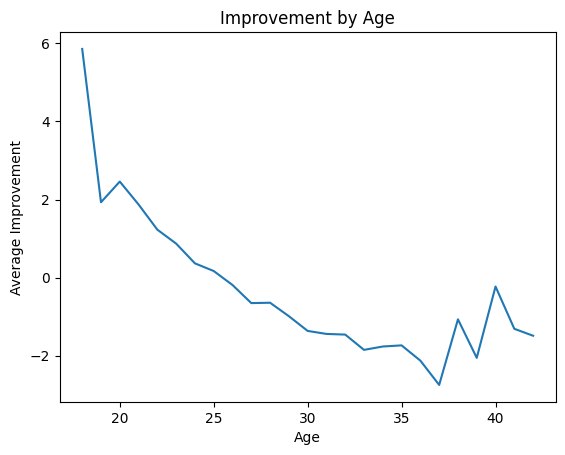

In [ ]:
age_group = df.groupby("age")["improvement"].mean()

age_group.plot()
plt.xlabel("Age")
plt.ylabel("Average Improvement")
plt.title("Improvement by Age")
plt.show()

In [ ]:
df["age"].value_counts().sort_index()

,count
age,
18.0,3
19.0,73
20.0,270
21.0,469
22.0,694
23.0,996
24.0,1051
25.0,948
26.0,892


In [19]:
df[["age", "improvement"]].corr()

,age,improvement
age,1.000000,-0.275737
improvement,-0.275737,1.000000


In [20]:
df[["usg_change", "improvement"]].corr()

,usg_change,improvement
usg_change,1.000000,0.298826
improvement,0.298826,1.000000


In [ ]:
df["ts_change"] = df["ts_pct_next"] - df["ts_pct"]

df[["ts_change", "improvement"]].corr()

,ts_change,improvement
ts_change,1.000000,0.542649
improvement,0.542649,1.000000


In [ ]:
df[["age", "usg_change", "ts_change", "improvement"]].corr()

,age,usg_change,ts_change,improvement
age,1.000000,-0.087575,-0.081673,-0.275737
usg_change,-0.087575,1.000000,0.024725,0.298826
ts_change,-0.081673,0.024725,1.000000,0.542649
improvement,-0.275737,0.298826,0.542649,1.000000


In [ ]:
from sklearn.linear_model import LinearRegression

X = df[["age", "usg_change", "ts_change"]]
y = df["improvement"]

model = LinearRegression()
model.fit(X, y)

print(model.coef_)

[-0.19985748 28.74957925 21.07982644]


# Final takeaway:
# - Efficiency (TS%) has the strongest relationship with improvement
# - Usage has a moderate impact
# - Age has a smaller negative effect

# This suggests that player development is driven more by
# improvements in skill (efficiency) rather than just increased opportunity.